In [1]:
import numpy as np
import pandas as pd
import h5py
import os
import sys

import matplotlib.pyplot as plt
from matplotlib import cm
import plotly.graph_objects as go

sys.path.insert(0, "..")
from plot_style import *

import astropy.units as u
from astropy.coordinates import SkyCoord
from astropy.io import fits

from scipy import stats

In [2]:
from astropy.cosmology import FlatLambdaCDM 
from astropy.cosmology import z_at_value
cosmo = FlatLambdaCDM(H0 = 70, Om0 = 0.3)

In [3]:
grid_alpha = 0.1
grid_color = 'grey'
grid_ls = "-"

In [4]:
h5file = "/Users/jordan/Documents/Epochs/data/analysis_data.h5"

In [5]:
filters_info = pd.read_csv("/Users/jordan/Documents/Epochs/data/throughputs/wavelengths.txt", delimiter=" ")

prospect_with_agn = pd.read_csv(
    "/Users/jordan/Documents/Epochs/data/prospect/photoZ_bc03_snorm_fritz_norm_eazy_no_tau_birth_astro_cat.csv"
)
prospect_without_agn = pd.read_csv(
    "/Users/jordan/Documents/Epochs/data/prospect/photoZ_bc03_snorm_norm_eazy_no_tau_birth_astro_cat.csv"
)
prospect_lrd = pd.read_csv(
    "/Users/jordan/Documents/Epochs/data/prospect/photoZ_bc03_snorm_LRDLIU_norm_eazy_no_tau_birth_lrd_astro_cat.csv"
)
prospect_robust = pd.read_csv(
    "/Users/jordan/Documents/Epochs/data/prospect/photoZ_bc03_snorm_fritz_robust_catalogue.csv"
)
prospect_robust_photom = pd.read_csv(
    "/Users/jordan/Documents/Epochs/data/prospect/photoZ_bc03_snorm_fritz_robust_fit_photom.csv"
)

# Compare EAZY specz and photoz

In [9]:
def compute_sigmaNMAD(zspec, zphot, zphot_lim=0):
    zspec = np.array(zspec)
    zphot = np.array(zphot)
    
    idx = (zphot > zphot_lim) & (~np.isnan(zphot))
    deltaz = zphot[idx] - zspec[idx]
    
    sigmaNMAD = 1.48 * np.median(np.abs((deltaz - np.median(deltaz)) / (1 + zspec[idx])))
    return sigmaNMAD


def compute_outliers(zspec, zphot, thresh=0.15, zphot_lim=-2):
    zspec = np.array(zspec)
    zphot = np.array(zphot)
    
    idx = (zphot > zphot_lim) & (~np.isnan(zphot))
    deltaz = np.abs(zphot[idx] - zspec[idx])
    
    Noutlier = np.sum(deltaz / (1 + zspec[idx]) > thresh)
    outlier_frac = Noutlier / len(zspec[idx])
    
    print(f"Noutlier: {Noutlier}")
    print(f"N total:  {len(zspec[idx])}")
    
    return outlier_frac, deltaz / (1 + zspec[idx]) > thresh

In [10]:
jades_specz = pd.read_hdf(
    h5file, 
    "specz/jades_match/specz"
)
agn_blue_eazy_spec_stats = pd.read_hdf(
    h5file, 
    "specz/jades_match/agn_blue_sfhz_stats"
)
agn_blue_eazy_stats = pd.read_hdf(
    h5file, 
    "eazy/eazy_stats/agn_blue_sfhz"
)

juodzbalis26_match = pd.read_hdf(
    h5file, 
    "specz/juodzbaliz_match/specz"
)
prospect_juodzbalis26_match = pd.read_hdf(
    h5file, 
    "specz/juodzbaliz_match/prospect_with_agn"
)

/Users/jordan/miniconda3/envs/space/lib/python3.14/site-packages/tables/path.py:146: NaturalNameWarning: object name is not a valid Python identifier: 'object_id.1'; it does not match the pattern ``^[a-zA-Z_][a-zA-Z0-9_]*$``; you will not be able to use natural naming to access this object; using ``getattr()`` will still work, though
  check_attribute_name(name)
/Users/jordan/miniconda3/envs/space/lib/python3.14/site-packages/tables/path.py:146: NaturalNameWarning: object name is not a valid Python identifier: 'category.1'; it does not match the pattern ``^[a-zA-Z_][a-zA-Z0-9_]*$``; you will not be able to use natural naming to access this object; using ``getattr()`` will still work, though
  check_attribute_name(name)
/Users/jordan/miniconda3/envs/space/lib/python3.14/site-packages/tables/path.py:146: NaturalNameWarning: object name is not a valid Python identifier: 'ID.1'; it does not match the pattern ``^[a-zA-Z_][a-zA-Z0-9_]*$``; you will not be able to use natural naming to access

Noutlier: 2
N total:  134


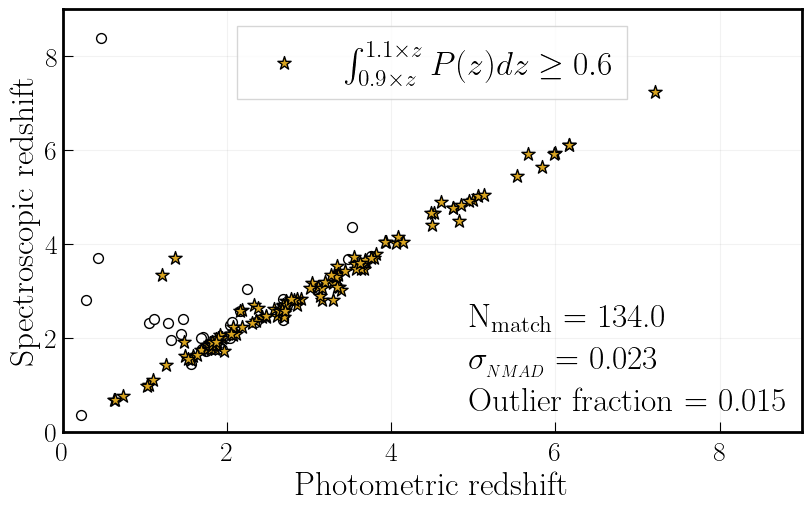

In [137]:
fig, ax = plt.subplots(1,1, figsize = (8,5))
ax = [ax]
ax[0].scatter(
    agn_blue_eazy_spec_stats["z_ml"][~(agn_blue_eazy_spec_stats["zbestPzIntegral"] >= 0.60)],
    jades_specz["z_Spec"][~(agn_blue_eazy_spec_stats["zbestPzIntegral"] >= 0.60)],
    edgecolor = 'black',
    facecolor = 'white',
    s = 50
)
ax[0].scatter(
    agn_blue_eazy_spec_stats["z_ml"][agn_blue_eazy_spec_stats["zbestPzIntegral"] >= 0.60],
    jades_specz["z_Spec"][agn_blue_eazy_spec_stats["zbestPzIntegral"] >= 0.60],
    edgecolor = 'black',
    facecolor = 'goldenrod',
    marker = "*",
    s = 100,
    label = r"$\int^{1.1 \times z}_{0.9 \times z} P(z)dz \geq 0.6$"
)

ax[0].text(
    0.55, 0.25, 
    rf"N$_{{\mathrm{{match}}}}$ =  {len(agn_blue_eazy_spec_stats["z_ml"][agn_blue_eazy_spec_stats["zbestPzIntegral"] >= 0.60]):.1f}", transform=ax[0].transAxes
)
ax[0].text(
    0.55, 0.15, 
    rf"$\sigma_{{_{{NMAD}}}} = $ {compute_sigmaNMAD(zspec=jades_specz["z_Spec"][agn_blue_eazy_spec_stats["zbestPzIntegral"] >= 0.60], zphot=agn_blue_eazy_spec_stats["z_ml"][agn_blue_eazy_spec_stats["zbestPzIntegral"] >= 0.60]):.3f}", transform=ax[0].transAxes
)
ax[0].text(
    0.55, 0.05, 
    rf"Outlier fraction = {compute_outliers(zspec=jades_specz["z_Spec"][agn_blue_eazy_spec_stats["zbestPzIntegral"] >= 0.60], zphot=agn_blue_eazy_spec_stats["z_ml"][agn_blue_eazy_spec_stats["zbestPzIntegral"] >= 0.60])[0]:.3f}", transform=ax[0].transAxes
)

ax[0].set_xlim([0,9])
ax[0].set_ylim([0,9])

ax[0].set_xlabel("Photometric redshift")
ax[0].set_ylabel("Spectroscopic redshift")

ax[0].grid(grid_ls, color = grid_color, alpha = grid_alpha)
ax[0].legend(fancybox = False)

fig.savefig(
    "/Users/jordan/Documents/Epochs/plots/jades_specz.pdf", 
    dpi = 240,
    bbox_inches="tight"
)


# SFR-Mstar

In [7]:
# lbt_bins = np.append(np.arange(9.0, 13.5, 0.5), (13.1))
lbt_bins = np.arange(8.0, 13.5, 0.5)
zbins = z_at_value(cosmo.lookback_time, lbt_bins*u.Gyr).value
# zbins = [2,3,4,5,6,7,8,9,10,11]
zmids = zbins[:-1] + np.diff(zbins)/2.0

print(len(zmids))

10


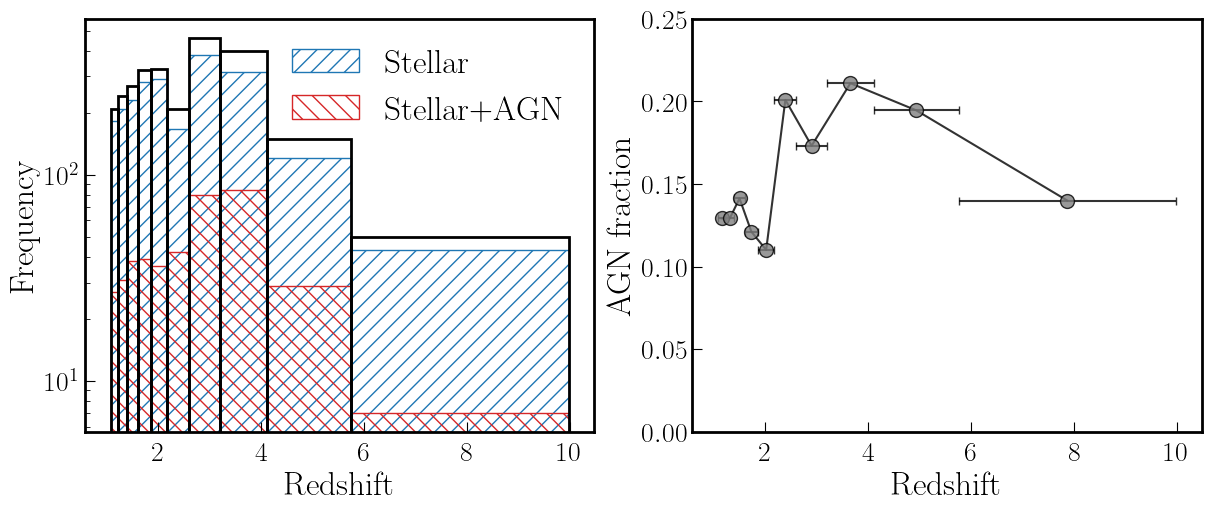

In [8]:
fig, ax = plt.subplots(1,2, figsize = (12,5), layout = 'constrained')
stellar_counts, stellar_bin_edges, stellar_patches = ax[0].hist(
    prospect_robust["zQ50"][prospect_robust["FitType"] == "Stellar"], 
    facecolor = "none",
    edgecolor = "tab:blue", 
    hatch = "//", 
    bins=zbins, 
    label = "Stellar"
)
stellarAGN_counts, stellarAGN_bin_edges, stellarAGN_patches = ax[0].hist(
    prospect_robust["zQ50"][prospect_robust["FitType"] == "StellarAGN"], 
    facecolor = "none",
    edgecolor = "tab:red", 
    hatch = "\\\\", 
    bins=zbins, 
    label = "Stellar+AGN"
)
tot_counts, tot_bin_edges, tot_patches = ax[0].hist(
    prospect_robust["zQ50"], 
    facecolor = "none",
    edgecolor = "black", 
    # hatch = "\\//",
    # alpha = 0.4, 
    bins=zbins,
    lw = 2
)

ax[0].set_yscale("log")

ax[0].set_xlim([zbins[0]-0.5, zbins[-1]+0.5])
ax[0].set_xticks([2.0, 4.0, 6.0, 8.0, 10.0])

ax[0].legend(frameon = False)
ax[0].set_xlabel("Redshift")
ax[0].set_ylabel("Frequency")

ax[1].errorbar(
    zmids, 
    stellarAGN_counts/tot_counts, 
    xerr = [np.diff(zbins)*0.5],
    marker = "o", 
    markersize = 10,
    markerfacecolor = "grey",
    markeredgecolor = "black",
    color = "black",
    ecolor = "black", 
    alpha = 0.8,
    capsize = 3
)
ax[1].set_xlim([zbins[0]-0.5, zbins[-1]+0.5])
ax[1].set_xticks([2.0, 4.0, 6.0, 8.0, 10.0])
ax[1].set_ylim([0, 0.25])

ax[1].set_xlabel("Redshift")
ax[1].set_ylabel("AGN fraction")

plt.savefig("/Users/jordan/Documents/Epochs/plots/redshift_hist.pdf",     bbox_inches="tight", dpi = 240)

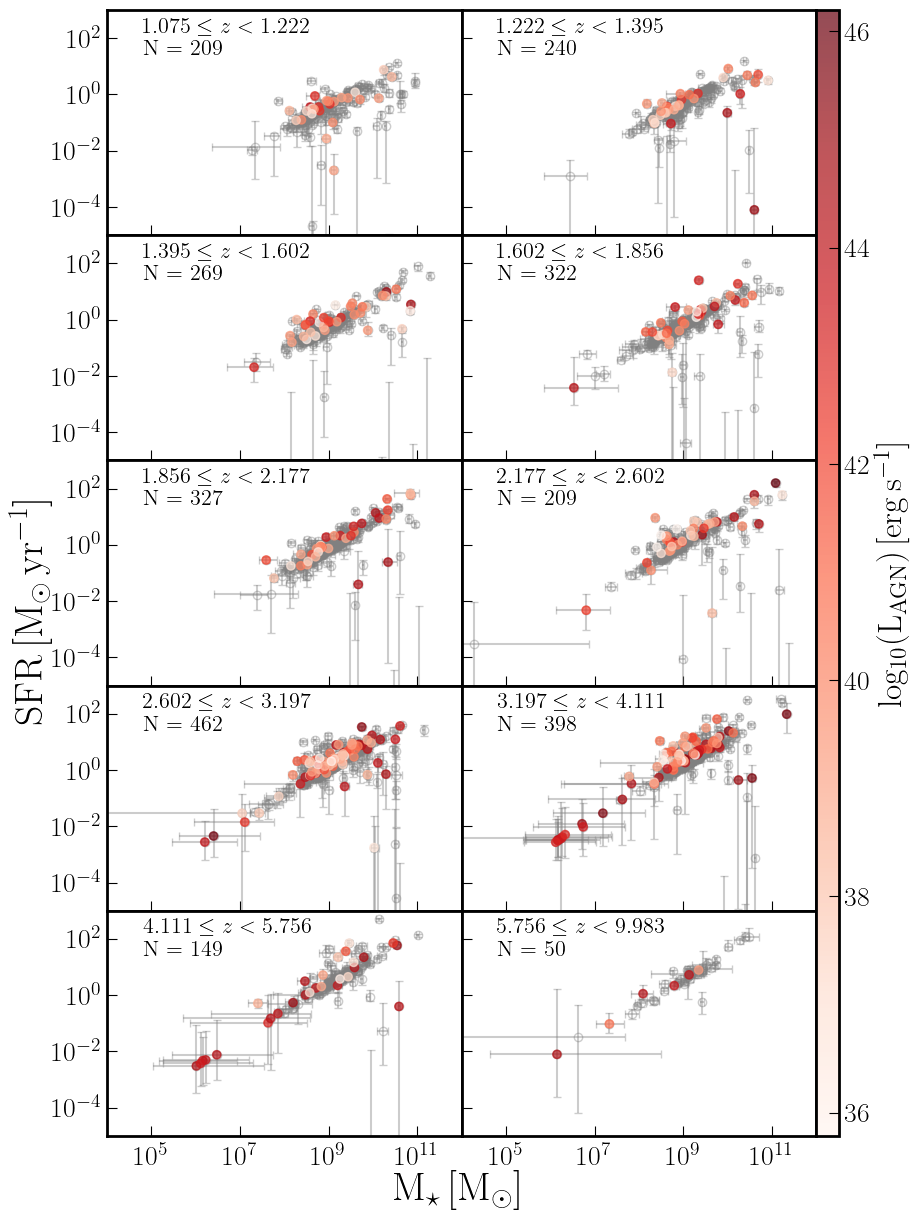

In [9]:
fig, ax = plt.subplots(5,2, figsize = (9,12), sharex=True, sharey=True, layout='constrained')
fig.get_layout_engine().set(h_pad=0, w_pad=0, hspace=0, wspace=0)

ax = ax.flatten()

ztot_zidx = (prospect_robust["zQ50"] >= zbins[0]) & (prospect_robust["zQ50"] < zbins[-1])

for i in range(len(zmids)):
    zidx = (prospect_robust["zQ50"] >= zbins[i]) & (prospect_robust["zQ50"] < zbins[i+1])

    ax[i].errorbar(
        prospect_robust["StellarMassQ50"][zidx],
        prospect_robust["SFR10Q50"][zidx],
        xerr = [prospect_robust["StellarMass_lo"][zidx], prospect_robust["StellarMass_hi"][zidx]],
        yerr = [prospect_robust["SFR10_lo"][zidx], prospect_robust["SFR10_hi"][zidx]],
        fmt = "o",
        markerfacecolor = "none",
        markeredgecolor = "grey",
        ecolor = "grey",
        capsize = 3,
        alpha = 0.4
    )

    sc_ = ax[i].scatter(
        prospect_robust["StellarMassQ50"][zidx],
        prospect_robust["SFR10Q50"][zidx],
        c = np.log10(prospect_robust["AGNlumQ50"][zidx]),
        vmin = np.nanmin(np.log10(prospect_robust["AGNlumQ50"][ztot_zidx])),
        vmax = np.nanmax(np.log10(prospect_robust["AGNlumQ50"][ztot_zidx])),
        zorder = 100, 
        cmap='Reds',
        alpha = 0.7
    )

    ax[i].text(
        0.1,
        0.9,
        rf"${zbins[i]:.3f} \leq z < {zbins[i+1]:.3f}$",
        transform=ax[i].transAxes,
        fontsize = 16
    )
    ax[i].text(
        0.1,
        0.8,
        f"N = {sum(zidx)}",
        transform=ax[i].transAxes,
        fontsize = 16
    )

    ax[i].set_xscale('log')
    ax[i].set_yscale('log')

    ax[i].set_xlim([1e4, 1e12])
    ax[i].set_ylim([1e-5, 1e3])

    ax[i].set_xticks([1e5, 1e7, 1e9, 1e11])
    ax[i].set_yticks([1e-4, 1e-2, 1e0, 1e2])

# cbar_ax = fig.add_axes([0.87, 0.05, 0.02, 0.9])  # [left, bottom, width, height]
cbar = fig.colorbar(sc_, ax = ax, label=r'$\mathrm{log_{10}(L_{AGN}) \, [erg \, s^{-1}]}$', pad = 0.0, aspect = 50)

fig.supxlabel(r"$\mathrm{M_{\star} \, [M_{\odot}]}$")
fig.supylabel(r"$\mathrm{SFR \, [M_{\odot} \, yr^{-1}]}$")

fig.savefig(
    "/Users/jordan/Documents/Epochs/plots/sfr-mstar-z.pdf", 
    dpi = 240,
    bbox_inches="tight"
)


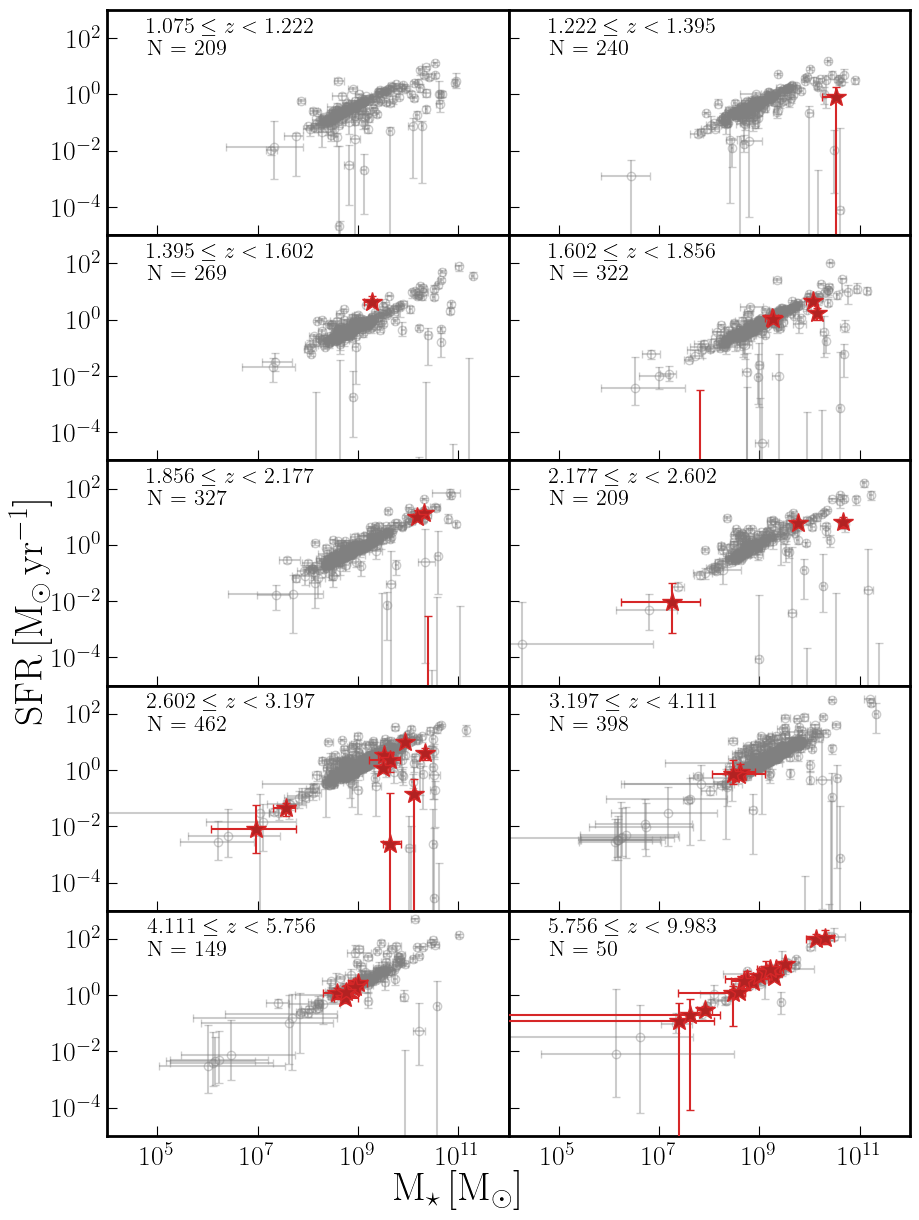

In [182]:
fig, ax = plt.subplots(5,2, figsize = (9,12), sharex=True, sharey=True, layout='constrained')
fig.get_layout_engine().set(h_pad=0, w_pad=0, hspace=0, wspace=0)

ax = ax.flatten()

for i in range(len(zmids)):
    zidx = (prospect_robust["zQ50"] >= zbins[i]) & (prospect_robust["zQ50"] < zbins[i+1])

    ax[i].errorbar(
        prospect_robust["StellarMassQ50"][zidx],
        prospect_robust["SFR10Q50"][zidx],
        xerr = [prospect_robust["StellarMass_lo"][zidx], prospect_robust["StellarMass_hi"][zidx]],
        yerr = [prospect_robust["SFR10_lo"][zidx], prospect_robust["SFR10_hi"][zidx]],
        fmt = "o",
        markerfacecolor = "none",
        markeredgecolor = "grey",
        ecolor = "grey",
        capsize = 3,
        alpha = 0.4
    )

    ax[i].errorbar(
        prospect_lrd["StellarMassQ50"][zidx],
        prospect_lrd["SFR10Q50"][zidx],
        xerr = [prospect_lrd["StellarMass_lo"][zidx], prospect_lrd["StellarMass_hi"][zidx]],
        yerr = [prospect_lrd["SFR10_lo"][zidx], prospect_lrd["SFR10_hi"][zidx]],
        fmt = "*",
        markersize = 15,
        markerfacecolor = "firebrick",
        markeredgecolor = "tab:red",
        ecolor = "tab:red",
        capsize = 3, 
        zorder = 200
    )

    # sc_ = ax[i].scatter(
    #     prospect_robust["StellarMassQ50"][zidx],
    #     prospect_robust["SFR10Q50"][zidx],
    #     c = np.log10(prospect_robust["AGNlumQ50"][zidx]),
    #     zorder = 100, 
    #     cmap='Spectral_r',
    #     alpha = 0.5
    # )

    ax[i].text(
        0.1,
        0.9,
        rf"${zbins[i]:.3f} \leq z < {zbins[i+1]:.3f}$",
        transform=ax[i].transAxes,
        fontsize = 16
    )
    ax[i].text(
        0.1,
        0.8,
        f"N = {sum(zidx)}",
        transform=ax[i].transAxes,
        fontsize = 16
    )
    # ax[i].text(
    #     0.1,
    #     0.8,
    #     f"N - LRD = {sum(~np.isnan(prospect_lrd["StellarMassQ50"][zidx]))}",
    #     transform=ax[i].transAxes,
    #     fontsize = 16
    # )

    ax[i].set_xscale('log')
    ax[i].set_yscale('log')

    ax[i].set_xlim([1e4, 1e12])
    ax[i].set_ylim([1e-5, 1e3])

    ax[i].set_xticks([1e5, 1e7, 1e9, 1e11])
    ax[i].set_yticks([1e-4, 1e-2, 1e0, 1e2])

# fig.colorbar(sc_, ax=ax, label=r'$\mathrm{log_{10}(L_{AGN}) \, [erg \, s^{-1}]}$', pad = 0.01)

fig.supxlabel(r"$\mathrm{M_{\star} \, [M_{\odot}]}$")
fig.supylabel(r"$\mathrm{SFR \, [M_{\odot} \, yr^{-1}]}$")

fig.savefig(
    "/Users/jordan/Documents/Epochs/plots/sfr-mstar-z_lrds.pdf", 
    dpi = 240,
    bbox_inches="tight"
)


## Selected LRDs

In [ ]:
LRD_selection_idx = np.loadtxt("/Users/jordan/Documents/Epochs/data/prospect/LRD_colour_selection_IDs.txt")

[  30.   62.   71.   87.  147.  154.  212.  215.  220.  261.  316.  350.
  377.  382.  398.  435.  501.  542.  546.  585.  688.  806.  859.  866.
 1048. 1128. 1281. 1410. 1457. 1498. 1643. 1681. 1725. 1825. 1910. 2000.
 2152. 2257. 2268. 2342. 2549. 2588. 2628. 2843. 2846. 2968. 3169. 3444.
 3499. 3588. 3787. 3928. 3986. 4313. 4587. 4764. 4813. 4874. 5051.]


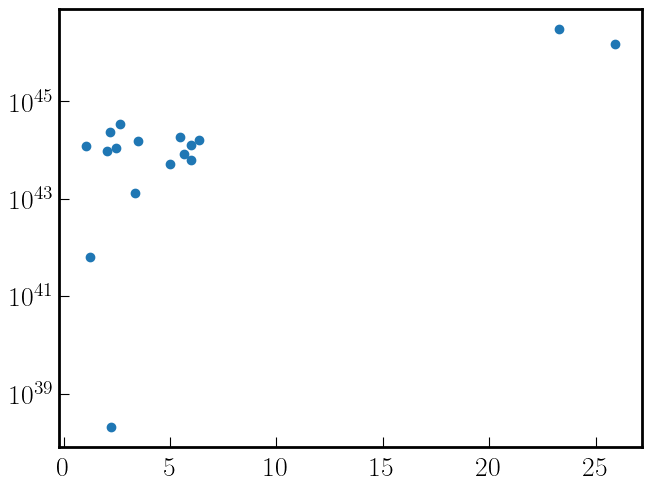

In [43]:
plt.scatter(prospect_robust["zQ50"][LRD_selection_idx-1],prospect_robust["AGNlumQ50"][LRD_selection_idx-1])
plt.yscale('log')

(1e+35, 1e+49)

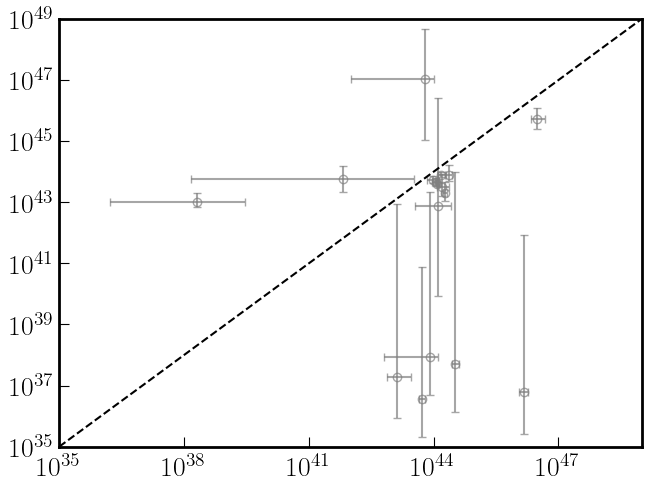

In [36]:
fig, ax = plt.subplots(1, 1)
ax.errorbar(
        prospect_robust["AGNlumQ50"],
        prospect_lrd["AGNlumQ50"],
        xerr = [prospect_robust["AGNlum_lo"], prospect_robust["AGNlum_hi"]],
        yerr = [prospect_lrd["AGNlum_lo"], prospect_lrd["AGNlum_hi"]],
        fmt = "o",
        markerfacecolor = "none",
        markeredgecolor = "grey",
        ecolor = "grey",
        capsize = 3,
        alpha = 0.7
    )
ax.plot(10**np.linspace(35,49,2), 10**np.linspace(35,49,2), color = "black", ls = "--")

# ax.hist(
#    np.log10(prospect_robust["AGNlumQ50"]) - np.log10(prospect_lrd["AGNlumQ50"]) 
# )

# print(f"Median = {np.nanmedian(np.log10(prospect_robust["AGNlumQ50"]) - np.log10(prospect_lrd["AGNlumQ50"])):.3}")
# fig.colorbar(sc_, ax=ax, label=r'$\mathrm{log_{10}(L_{AGN}) \, [erg \, s^{-1}]}$', pad = 0.01, ticks = [0,1])

ax.set_xscale('log')
ax.set_yscale('log')

ax.set_xlim([1e35, 1e49])
ax.set_ylim([1e35, 1e49])

In [44]:
import re

# Get columns matching pattern like F435W_fit_Q50, F606W_fit_Q50 etc
q50_cols = [col for col in prospect_robust_photom.columns if re.search(r'F\d+W_fit_Q50', col)]
# Or with pandas filter
q50_cols = prospect_robust_photom.filter(regex=r'F\d+[LPMW]+_fit_Q50').columns.tolist()
AGN_q50_cols = prospect_robust_photom.filter(regex=r'F\d+[LPMW]+_fit_AGN_Q50').columns.tolist()

# mask = (prospect_robust_photom[AGN_q50_cols] > 0).all(axis=1)

ValueError: x and y must be the same size

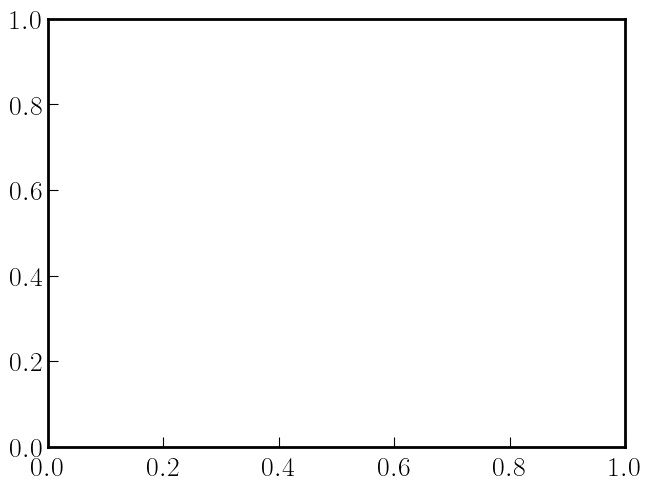

In [45]:
plt.scatter(filters_info["cenwave"], np.sum(prospect_robust_photom[AGN_q50_cols], axis = 0)/np.sum(prospect_robust_photom[q50_cols], axis = 0))
# plt.scatter(filters_info["cenwave"], np.sum(prospect_robust_photom[AGN_q50_cols], axis = 0))
# plt.yscale("log")
plt.xscale("log")

In [46]:
prospect_robust_photom[AGN_q50_cols][mask]

,HST_ACSWFC_F435W_fit_AGN_Q50,HST_ACSWFC_F606W_fit_AGN_Q50,JWST_NIRCAM_F070W_fit_AGN_Q50,HST_ACSWFC_F775W_fit_AGN_Q50,HST_ACSWFC_F814W_fit_AGN_Q50,JWST_NIRCAM_F090W_fit_AGN_Q50,HST_ACSWFC_F850LP_fit_AGN_Q50,JWST_NIRCAM_F115W_fit_AGN_Q50,JWST_NIRCAM_F150W_fit_AGN_Q50,JWST_NIRCAM_F162M_fit_AGN_Q50,...,JWST_NIRCAM_F460M_fit_AGN_Q50,JWST_NIRCAM_F480M_fit_AGN_Q50,JWST_MIRI_F560W_fit_AGN_Q50,JWST_MIRI_F770W_fit_AGN_Q50,JWST_MIRI_F1000W_fit_AGN_Q50,JWST_MIRI_F1280W_fit_AGN_Q50,JWST_MIRI_F1500W_fit_AGN_Q50,JWST_MIRI_F1800W_fit_AGN_Q50,JWST_MIRI_F2100W_fit_AGN_Q50,JWST_MIRI_F2550W_fit_AGN_Q50
0,4.491524e-08,8.912835e-08,1.308900e-07,1.555717e-07,1.707938e-07,2.113829e-07,2.132751e-07,3.381780e-07,5.543457e-07,6.281284e-07,...,4.431554e-06,4.944024e-06,6.221892e-06,9.227331e-06,1.182161e-05,1.603996e-05,2.095900e-05,2.606452e-05,2.873978e-05,3.121301e-05
4,9.802393e-36,5.334136e-42,5.264137e-43,3.290155e-40,3.247677e-37,2.252588e-21,3.235885e-21,5.556744e-21,5.726362e-10,6.540823e-10,...,7.517888e-09,7.870375e-09,9.937514e-09,1.546761e-08,2.280038e-08,3.219257e-08,4.297427e-08,5.682462e-08,6.874615e-08,9.605409e-08
7,3.322940e-14,9.951388e-14,5.264344e-13,1.376773e-12,5.081697e-12,1.721831e-11,1.717241e-11,8.167963e-11,3.053658e-10,4.747523e-10,...,8.824740e-07,1.137454e-06,2.668135e-06,8.488463e-06,1.611274e-05,2.353557e-05,2.760480e-05,3.066751e-05,2.601841e-05,3.157209e-05
9,3.771602e-08,8.720459e-08,1.345362e-07,1.673704e-07,1.943275e-07,2.679791e-07,2.700405e-07,5.352922e-07,1.206017e-06,1.401509e-06,...,1.293423e-05,1.222337e-05,1.376680e-05,1.813391e-05,2.633656e-05,3.188313e-05,3.525410e-05,3.415639e-05,3.167952e-05,3.944913e-05
10,6.213965e-13,8.738172e-13,1.056022e-12,1.152295e-12,1.199950e-12,1.367779e-12,1.389633e-12,2.204576e-12,3.673682e-12,4.641191e-12,...,2.231209e-11,2.367015e-11,2.699412e-11,3.673070e-11,5.590185e-11,5.836728e-11,6.237555e-11,5.385159e-11,6.340536e-11,7.706384e-11
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5637,4.315020e-10,1.634381e-09,2.144248e-09,2.257249e-09,2.299706e-09,2.420009e-09,2.424879e-09,2.750457e-09,3.532368e-09,3.798678e-09,...,9.926930e-09,1.042024e-08,1.236252e-08,1.802558e-08,2.526186e-08,3.296133e-08,3.846250e-08,4.429749e-08,4.866426e-08,5.423687e-08
5662,2.015765e-20,2.732256e-17,4.680400e-17,1.396848e-16,1.724805e-16,1.992465e-16,1.999333e-16,2.428437e-16,2.969182e-16,3.209928e-16,...,1.292401e-15,1.357194e-15,1.607515e-15,2.374117e-15,3.433727e-15,4.977049e-15,6.308144e-15,8.342047e-15,1.051845e-14,1.405314e-14
5663,6.410117e-13,9.333567e-13,1.050578e-12,1.111055e-12,1.129859e-12,1.192976e-12,1.201361e-12,1.373330e-12,1.587628e-12,1.635696e-12,...,3.139787e-12,3.303919e-12,3.891392e-12,5.469430e-12,7.155733e-12,8.669648e-12,9.608354e-12,1.080229e-11,1.151574e-11,1.437550e-11
5664,4.450798e-09,5.924091e-09,7.146839e-09,7.718800e-09,8.035030e-09,9.068117e-09,9.111977e-09,1.164606e-08,1.562033e-08,1.709116e-08,...,5.719618e-08,5.841444e-08,6.423047e-08,7.430648e-08,8.327158e-08,1.466486e-07,1.367442e-07,1.009205e-07,1.025400e-07,1.223824e-07


(1e-10, 0.001)

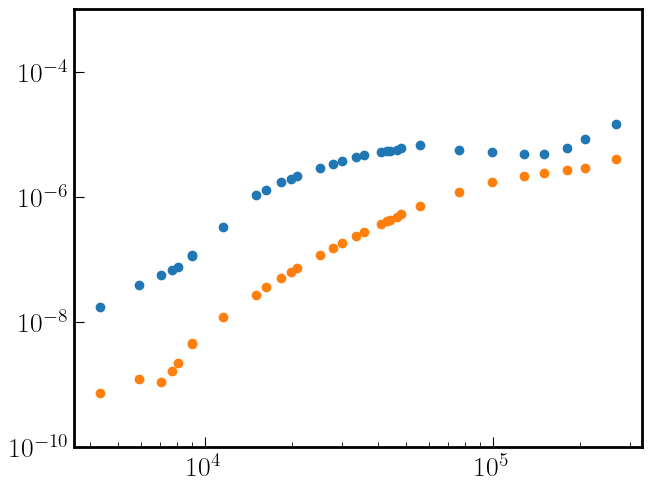

In [56]:
plt.scatter(
    filters_info["cenwave"], 
    prospect_robust_photom.iloc[29][q50_cols]
)
plt.scatter(
    filters_info["cenwave"], 
    prospect_robust_photom.iloc[29][AGN_q50_cols]
)

plt.xscale("log")
plt.yscale("log")
plt.ylim([1e-10, 1e-3])